# Burn AI FINAL — ConvNeXtV2 Nano + Curriculum U-Net++

**Demo để nộp bài** (không train lại): Ảnh đầu vào → 4-class **single-label classification** (`degree_1`, `degree_2`, `degree_3`, `None`) và **binary segmentation** (vùng nghi bỏng) → xác suất + mask + overlay + CSV kết quả.

**Cơ chế Safe Hybrid:** Giữ nguyên nhãn do classifier dự đoán. **KHÔNG** chuyển sang `None` chỉ vì mask trống; sự bất đồng giữa hai mô hình chỉ xuất cảnh báo để người xem kiểm tra.

**Cần 2 checkpoint đã huấn luyện (KHÔNG dùng pretrained classifier thay thế):**

1. `convnextv2_burn_4class_best.pth` — ConvNeXtV2 Nano, epoch 14, `best_val_macro_f1 ≈ 0.8537`.
2. `best_random_curriculum_seed2026.pt` — U-Net++ ResNet34, seed 2026, epoch 6, `valid_dice ≈ 0.7129`.

Các điểm hạn chế: mô hình chỉ cho **một nhãn mức độ bỏng trên một ảnh** và **một mask nhị phân**, không xác định nhiều mức độ trong cùng ảnh. Các dự đoán chỉ là kết quả thử nghiệm, **không dùng để chẩn đoán, phân loại mức độ tổn thương hoặc quyết định điều trị**.

### Cách chạy trên Google Colab

1. **Runtime → Change runtime type → GPU** (nếu có).
2. Chạy từ trên xuống (Runtime → Run all). Cho phép mount Google Drive khi được hỏi.
3. Trong **cell CẤU HÌNH**, giữ đường dẫn mặc định nếu hai file nằm đúng thư mục Drive đã dùng trước đó; nếu khác, sửa `CLS_CKPT` và `SEG_CKPT`.
4. Khi đến bước **TẢI ẢNH**, tải ảnh JPEG/PNG thử nghiệm lên (hoặc đặt `INPUT_DIR`). Kết quả tự lưu vào Google Drive.

> Trọng số **không được nhúng** vào notebook. Nếu checkpoint chỉ nằm trong cuộc trò chuyện, bạn vẫn cần tải các file `.pth` / `.pt` đó lên Google Drive hoặc tải trực tiếp trong phiên Colab.

In [30]:
# CELL 1 — CÀI THƯ VIỆN (Google Colab)
# Giữ phiên bản SMP 0.4–0.5 như pipeline Curriculum; không tải trọng số ImageNet từ mạng.
%pip -q install "timm>=1.0,<1.1" "segmentation-models-pytorch>=0.4,<0.6" "opencv-python-headless>=4.7" "matplotlib>=3.7" "pandas>=2.0" "Pillow>=9.0"

In [31]:
# CELL 2 — IMPORT + MOUNT DRIVE
import os, json, csv, time, re, zipfile
from pathlib import Path
from dataclasses import dataclass
from datetime import datetime
import numpy as np
import pandas as pd
import cv2
import torch
import timm
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from torchvision import transforms
from IPython.display import display

IS_COLAB = False
try:
    from google.colab import drive, files
    IS_COLAB = True
    drive.mount('/content/drive')
except ImportError:
    print('Không phải Colab: cung cấp đường dẫn file local trong CFG và INPUT_DIR.')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| torch:', torch.__version__, '| timm:', timm.__version__, '| smp:', smp.__version__)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu | torch: 2.11.0+cpu | timm: 1.0.30 | smp: 0.5.0


In [32]:
# CELL 3 — CẤU HÌNH. CHỈ CẦN SỬA ĐƯỜNG DẪN NẾU FILE Ở CHỖ KHÁC.
@dataclass
class CFG:
    CLS_CKPT: str = '/content/drive/MyDrive/Bao_Cao_Thuc_Nghiem_AI/convnextv2_burn_4class_best.pth'
    SEG_CKPT: str = '/content/drive/MyDrive/burn_curriculum_v5_results/best_random_curriculum_seed2026.pt'
    OUTPUT_DIR: str = '/content/drive/MyDrive/Bao_Cao_Thuc_Nghiem_AI/Burn_AI_FINAL_outputs'
    # Sử dụng thư mục nhatruongsucvat trên Google Drive làm đầu vào
    INPUT_DIR: str = '/content/drive/MyDrive/nhatruongsucvat'
    # Tắt tự động upload do đã có thư mục ảnh đầu vào cụ thể
    AUTO_UPLOAD: bool = False
    CLS_SIZE: int = 224
    SEG_SIZE: int = 320
    MASK_THRESHOLD: float = 0.50   # Giữ đúng threshold của benchmark; không tinh chỉnh theo test.
    DISAGREE_AREA_FRAC: float = 0.01  # Chỉ cảnh báo, không đổi nhãn hoặc tối ưu threshold test.
    MAX_PREVIEW: int = 8

cfg = CFG()
CLASS_NAMES = ['degree_1', 'degree_2', 'degree_3', 'None']
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
assert 0 < cfg.MASK_THRESHOLD < 1
assert cfg.CLS_SIZE == 224 and cfg.SEG_SIZE == 320

# Không ghi kết quả vào thư mục gốc nếu không mount được Drive.
if not Path('/content/drive/MyDrive').is_dir() and cfg.OUTPUT_DIR.startswith('/content/drive/'):
    cfg.OUTPUT_DIR = '/content/Burn_AI_FINAL_outputs'
OUT = Path(cfg.OUTPUT_DIR)
OUT.mkdir(parents=True, exist_ok=True)
print('Output:', OUT)

Output: /content/drive/MyDrive/Bao_Cao_Thuc_Nghiem_AI/Burn_AI_FINAL_outputs


In [33]:
# CELL 4 — XÁC ĐỊNH CHECKPOINT, KIỂM TRA METADATA (KHÔNG NẠP NHẦM PRETRAINED)
def resolve_ckpt(configured, safe_names):
    base = Path(configured)
    candidates = [base] + [base.with_name(name) for name in safe_names]
    for root in [Path('/content'), Path('/mnt/data'), Path.cwd()]:
        candidates += [root / name for name in safe_names]
    for p in candidates:
        if p.is_file():
            return p
    msg = '\n'.join('   ' + str(p) for p in candidates)
    raise FileNotFoundError('Không tìm thấy checkpoint. Đổi đường dẫn trong CFG hoặc upload file checkpoint vào Colab. Đã kiểm tra:\n' + msg)

CLS_PATH = resolve_ckpt(cfg.CLS_CKPT, ('convnextv2_burn_4class_best.pth', 'convnextv2_burn_4class_best (1).pth'))
SEG_PATH = resolve_ckpt(cfg.SEG_CKPT, ('best_random_curriculum_seed2026.pt',))

def safe_load(path):
    # Chỉ dùng checkpoint tin cậy. weights_only=True từ chối pickle object tùy ý.
    return torch.load(str(path), map_location='cpu', weights_only=True)

cls_blob = safe_load(CLS_PATH)
seg_blob = safe_load(SEG_PATH)
if not isinstance(cls_blob, dict) or 'model_state_dict' not in cls_blob:
    raise ValueError('Classifier checkpoint thiếu model_state_dict: có thể bạn đã chọn nhầm file pretrained.')
if list(cls_blob.get('class_names', [])) != CLASS_NAMES:
    raise ValueError(f'Thứ tự class của checkpoint không khớp: {cls_blob.get("class_names")}')
if int(cls_blob.get('img_size', -1)) != cfg.CLS_SIZE:
    raise ValueError(f'Classifier checkpoint yêu cầu img_size={cls_blob.get("img_size")}')
if not isinstance(seg_blob, dict) or 'model' not in seg_blob:
    raise ValueError('Checkpoint segmentation phải có khóa model từ Curriculum v5.')
if seg_blob.get('mode') != 'random_curriculum':
    raise ValueError('Đây không phải checkpoint random_curriculum được chốt.')
print('Classifier:', CLS_PATH.name, '| epoch:', cls_blob.get('epoch'),
      '| best val Macro-F1:', cls_blob.get('best_val_macro_f1'))
print('Segmenter :', SEG_PATH.name, '| mode:', seg_blob.get('mode'),
      '| seed:', seg_blob.get('seed'), '| epoch:', seg_blob.get('epoch'),
      '| valid Dice:', seg_blob.get('valid_dice'))


Classifier: convnextv2_burn_4class_best.pth | epoch: 14 | best val Macro-F1: 0.8537414965986394
Segmenter : best_random_curriculum_seed2026.pt | mode: random_curriculum | seed: 2026 | epoch: 6 | valid Dice: 0.7129322742626437


In [34]:
# CELL 5 — NẠP 2 MÔ HÌNH BẰNG STRICT=True, KHÔNG TRAIN
# Đúng cấu hình như notebook Hard Cascade và Curriculum v5.
classifier = timm.create_model(
    'convnextv2_nano.fcmae_ft_in22k_in1k', pretrained=False,
    num_classes=4, drop_rate=0.4
)
segmenter = smp.UnetPlusPlus(
    encoder_name='resnet34', encoder_weights=None,
    in_channels=3, classes=1
)

def clean_state(state):
    if not isinstance(state, dict):
        raise TypeError('State dict không hợp lệ')
    out = {}
    for key, value in state.items():
        if not isinstance(value, torch.Tensor):
            continue
        k = key
        while k.startswith('module.') or k.startswith('model.'):
            k = k.split('.', 1)[1]
        out[k] = value
    return out

classifier.load_state_dict(clean_state(cls_blob['model_state_dict']), strict=True)
segmenter.load_state_dict(clean_state(seg_blob['model']), strict=True)
classifier = classifier.to(DEVICE).eval()
segmenter = segmenter.to(DEVICE).eval()
del cls_blob['model_state_dict'], seg_blob['model']
print('✅ Nạp thành công 2 checkpoint bằng strict=True; chưa thực hiện fine-tune.')


✅ Nạp thành công 2 checkpoint bằng strict=True; chưa thực hiện fine-tune.


## Suy luận Safe Hybrid

- **ConvNeXtV2**: RGB 224×224 → ImageNet normalization → Softmax 4 lớp.
- **Curriculum U-Net++**: RGB 320×320 → ImageNet normalization → Sigmoid → binary mask tại ngưỡng 0,50.
- **Đầu ra**: nhãn gốc của classifier + 4 xác suất Softmax + diện tích mask + overlay. Chỉ đánh dấu bất đồng giữa hai mô hình, **không override thành `None`**.
- Mask là **vùng nghi tổn thương**, không xác định chính xác mức độ bỏng của từng pixel.

In [35]:
# CELL 6 — HÀM DỰ ĐOÁN 1 ẢNH (NHẬN PIL RGB HOẶC ĐƯỜNG DẪN)
CLS_TF = transforms.Compose([
    transforms.Resize((cfg.CLS_SIZE, cfg.CLS_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN.tolist(), std=STD.tolist()),
])

def to_rgb_pil(src):
    if isinstance(src, (str, Path)):
        with Image.open(src) as im:
            return ImageOps.exif_transpose(im).convert('RGB').copy()
    if isinstance(src, Image.Image):
        return ImageOps.exif_transpose(src).convert('RGB')
    raise TypeError('Đầu vào phải là Path/string hoặc PIL.Image.')

@torch.inference_mode()
def predict_one(src):
    im = to_rgb_pil(src)
    rgb = np.asarray(im)
    h, w = rgb.shape[:2]

    # Classification 224x224, cùng validation transform của Hard Cascade.
    x_cls = CLS_TF(im).unsqueeze(0).to(DEVICE)
    cls_logits = classifier(x_cls)
    probs = torch.softmax(cls_logits.float(), dim=1)[0].cpu().numpy()
    class_idx = int(probs.argmax())

    # Segmentation 320x320, INTER_AREA + ImageNet normalization giống Curriculum v5.
    seg_rgb = cv2.resize(rgb, (cfg.SEG_SIZE, cfg.SEG_SIZE), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    seg_norm = (seg_rgb - MEAN) / STD
    x_seg = torch.from_numpy(np.ascontiguousarray(seg_norm.transpose(2, 0, 1))).unsqueeze(0).to(DEVICE)
    seg_prob_320 = torch.sigmoid(segmenter(x_seg).float())[0, 0].cpu().numpy()
    mask_320 = seg_prob_320 >= cfg.MASK_THRESHOLD
    # Đưa mask nhị phân về đúng tỷ lệ ảnh gốc (không tính độ bỏng theo từng pixel).
    mask_orig = cv2.resize(mask_320.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST) > 0
    mask_frac = float(mask_320.mean())

    label = CLASS_NAMES[class_idx]
    disagree = ((label == 'None' and mask_frac >= cfg.DISAGREE_AREA_FRAC) or
                (label != 'None' and not mask_320.any()))
    if label == 'None' and mask_frac >= cfg.DISAGREE_AREA_FRAC:
        note = 'Bất đồng: classifier dự đoán None nhưng segmenter tạo vùng nghi tổn thương.'
    elif label != 'None' and not mask_320.any():
        note = 'Bất đồng: classifier dự đoán bỏng nhưng segmenter không tìm thấy vùng tổn thương.'
    else:
        note = 'Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.'
    return dict(
        rgb=rgb, mask=mask_orig, mask320=mask_320,
        label=label, predicted_class_idx=class_idx,
        softmax_probs={n: float(p) for n, p in zip(CLASS_NAMES, probs)},
        predicted_class_probability=float(probs[class_idx]),
        mask_area_frac=mask_frac, disagreement=bool(disagree), note=note,
        original_size={'width': int(w), 'height': int(h)}
    )


In [36]:
# CELL 7 — HIỂN THỊ ẢNH GỐC, MASK, OVERLAY VÀ XÁC SUẤT

def make_overlay(rgb, mask, alpha=0.42):
    # Ảnh RGB chuẩn, mask kích thước gốc, tô vùng nghi tổn thương bằng màu đỏ.
    overlay = rgb.copy().astype(np.float32)
    red = np.zeros_like(overlay)
    red[:, :, 0] = 255
    overlay[mask] = (1 - alpha) * overlay[mask] + alpha * red[mask]
    return np.clip(overlay, 0, 255).astype(np.uint8)

def show_prediction(result, name='Ảnh kiểm tra'):
    rgb, mask = result['rgb'], result['mask']
    overlay = make_overlay(rgb, mask)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    axes[0].imshow(rgb); axes[0].set_title('Ảnh gốc'); axes[0].axis('off')
    axes[1].imshow(mask, cmap='gray', vmin=0, vmax=1); axes[1].set_title('Binary mask'); axes[1].axis('off')
    axes[2].imshow(overlay); axes[2].set_title('Overlay vùng nghi tổn thương'); axes[2].axis('off')
    names = list(result['softmax_probs'])
    ps = list(result['softmax_probs'].values())
    axes[3].barh(names, ps); axes[3].set_xlim(0, 1); axes[3].invert_yaxis()
    axes[3].set_xlabel('Softmax (chưa hiệu chuẩn)'); axes[3].set_title('Classification 4 lớp')
    fig.suptitle(f"{name} | {result['label']} ({result['predicted_class_probability']:.1%}) | mask {result['mask_area_frac']:.1%}", fontsize=11)
    plt.tight_layout(); plt.show(); plt.close(fig)
    print('Cảnh báo:', result['note'])

def save_prediction(result, prefix, target_dir):
    target_dir = Path(target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)
    Image.fromarray(result['rgb']).save(target_dir / (prefix + '_original.png'))
    Image.fromarray((result['mask'].astype(np.uint8) * 255)).save(target_dir / (prefix + '_mask.png'))
    Image.fromarray(make_overlay(result['rgb'], result['mask'])).save(target_dir / (prefix + '_overlay.png'))


In [37]:
# CELL 8 — CHỌN ẢNH TỪ THƯ MỤC HOẶC UPLOAD TRÊN COLAB
SUPPORTED_SUFFIXES = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
INPUT_FILES = []
if cfg.INPUT_DIR.strip():
    d = Path(cfg.INPUT_DIR)
    if not d.is_dir():
        raise FileNotFoundError('Không tìm thấy INPUT_DIR: ' + str(d))
    INPUT_FILES = sorted(p for p in d.iterdir() if p.is_file() and p.suffix.lower() in SUPPORTED_SUFFIXES)
elif IS_COLAB and cfg.AUTO_UPLOAD:
    print('Chọn một hoặc nhiều ảnh JPEG/PNG/WebP để dự đoán:')
    uploaded = files.upload()
    INPUT_FILES = [Path(name) for name in uploaded if Path(name).suffix.lower() in SUPPORTED_SUFFIXES]
else:
    print('Chưa có ảnh. Đặt cfg.INPUT_DIR đến folder chứa ảnh hoặc bật cfg.AUTO_UPLOAD trên Colab.')

if not INPUT_FILES:
    raise RuntimeError('Không có ảnh hợp lệ để suy luận. Sửa cfg.INPUT_DIR rồi chạy lại Cell 8.')
print('Số ảnh đã chọn:', len(INPUT_FILES))
for f in INPUT_FILES[:10]: print(' -', f)


Số ảnh đã chọn: 16
 - /content/drive/MyDrive/nhatruongsucvat/Human_skin_structure.jpg
 - /content/drive/MyDrive/nhatruongsucvat/bong-da(2)-800x450.jpg
 - /content/drive/MyDrive/nhatruongsucvat/bong_cap_do_3_la_gi_dau_hieu_nhan_biet_cach_xu_tri_va_phuc_hoi_dung_cach_1_e1f2656e30.webp
 - /content/drive/MyDrive/nhatruongsucvat/bong_cap_do_3_la_gi_dau_hieu_nhan_biet_cach_xu_tri_va_phuc_hoi_dung_cach_1a0904167a.jpg
 - /content/drive/MyDrive/nhatruongsucvat/images (1).jpg
 - /content/drive/MyDrive/nhatruongsucvat/images (2).jpg
 - /content/drive/MyDrive/nhatruongsucvat/images (3).jpg
 - /content/drive/MyDrive/nhatruongsucvat/images (4).jpg
 - /content/drive/MyDrive/nhatruongsucvat/images (6).jpg
 - /content/drive/MyDrive/nhatruongsucvat/mot_so_hinh_anh_so_cuu_khi_tre_bi_bong_1_728161f5bb.jpg


[1/16] Human_skin_structure.jpg -> degree_1 (81.1%), mask=0.0%, 0.51s


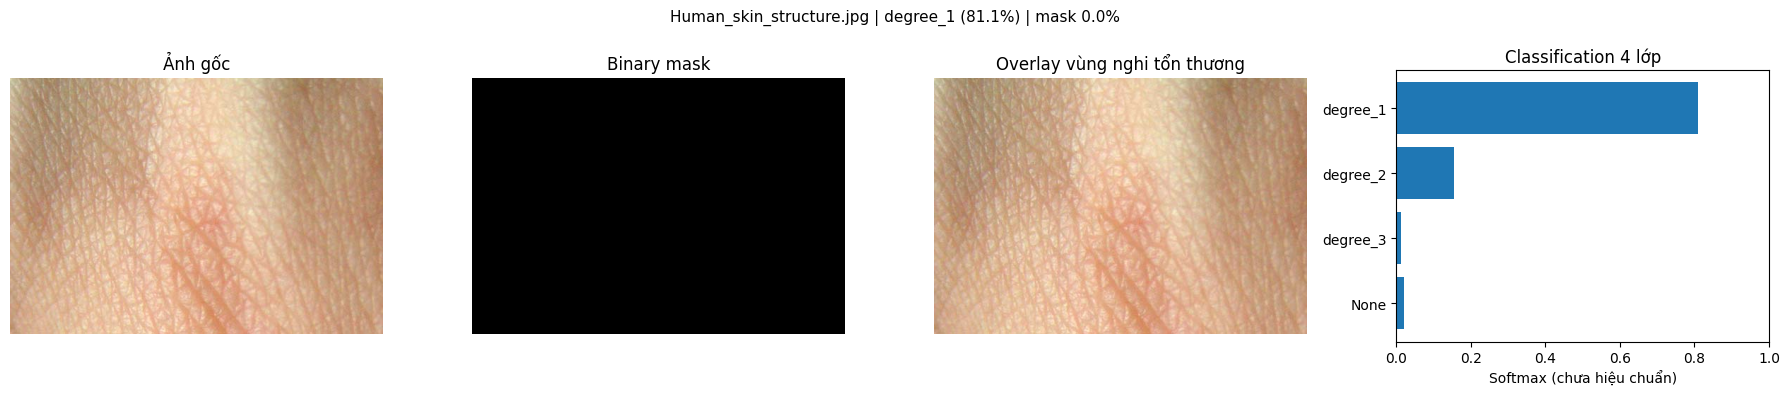

Cảnh báo: Bất đồng: classifier dự đoán bỏng nhưng segmenter không tìm thấy vùng tổn thương.
[2/16] bong-da(2)-800x450.jpg -> degree_1 (95.7%), mask=10.9%, 0.93s


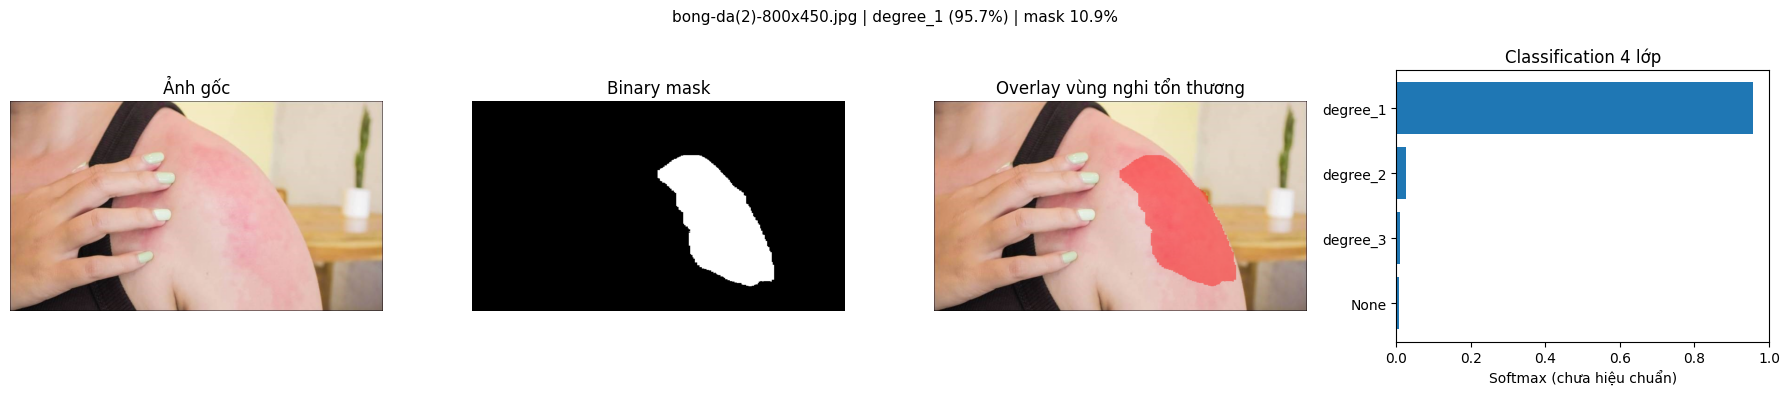

Cảnh báo: Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.
[3/16] bong_cap_do_3_la_gi_dau_hieu_nhan_biet_cach_xu_tri_va_phuc_hoi_dung_cach_1_e1f2656e30.webp -> degree_2 (91.5%), mask=25.9%, 0.65s


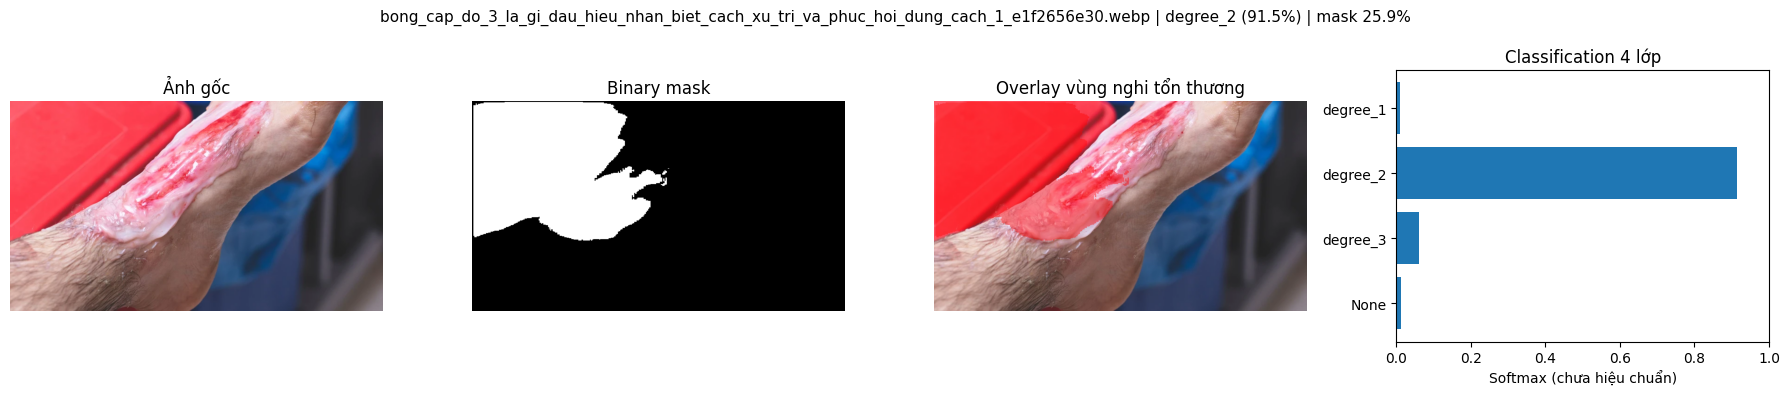

Cảnh báo: Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.
[4/16] bong_cap_do_3_la_gi_dau_hieu_nhan_biet_cach_xu_tri_va_phuc_hoi_dung_cach_1a0904167a.jpg -> degree_2 (88.4%), mask=9.0%, 0.60s


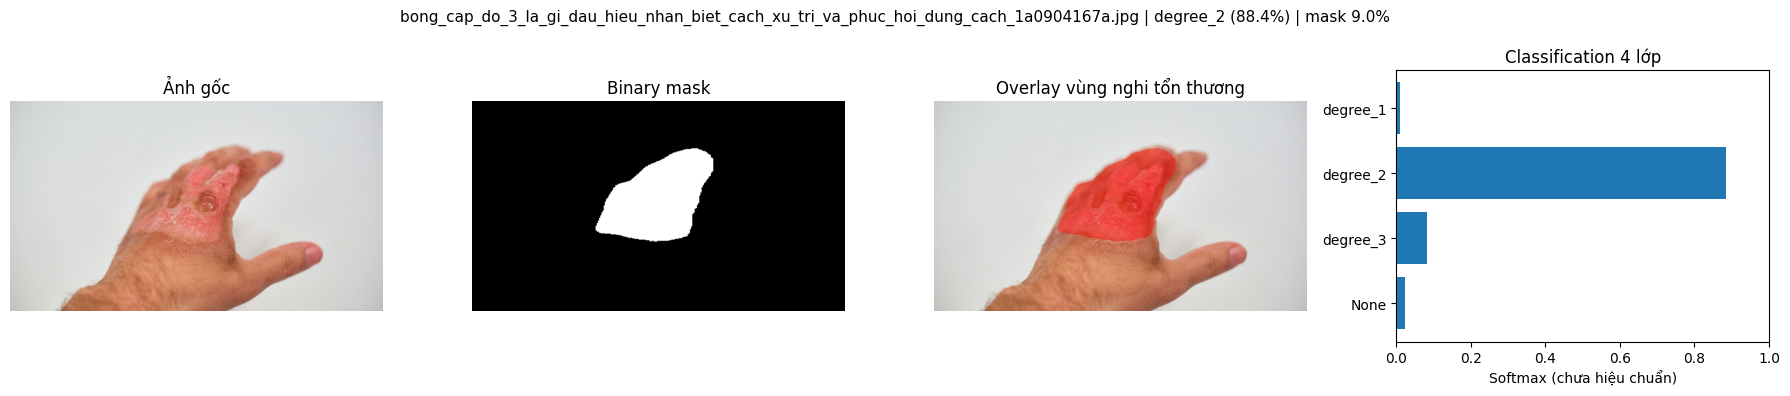

Cảnh báo: Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.
[5/16] images (1).jpg -> degree_3 (77.0%), mask=5.0%, 0.69s


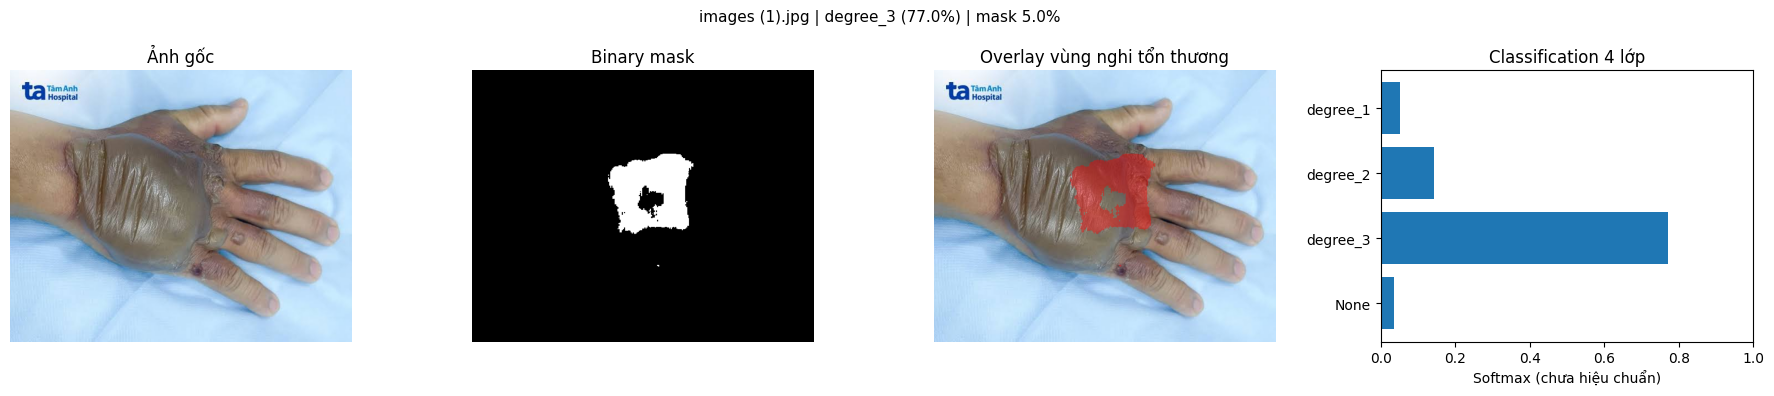

Cảnh báo: Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.
[6/16] images (2).jpg -> degree_3 (98.3%), mask=20.9%, 0.71s


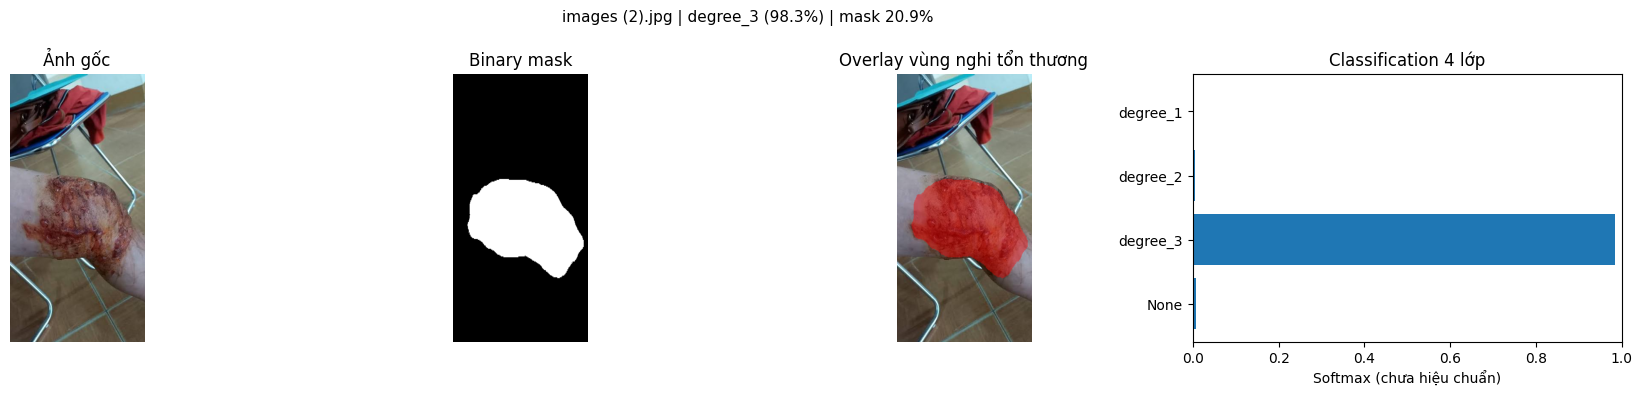

Cảnh báo: Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.
[7/16] images (3).jpg -> degree_3 (46.9%), mask=11.8%, 0.80s


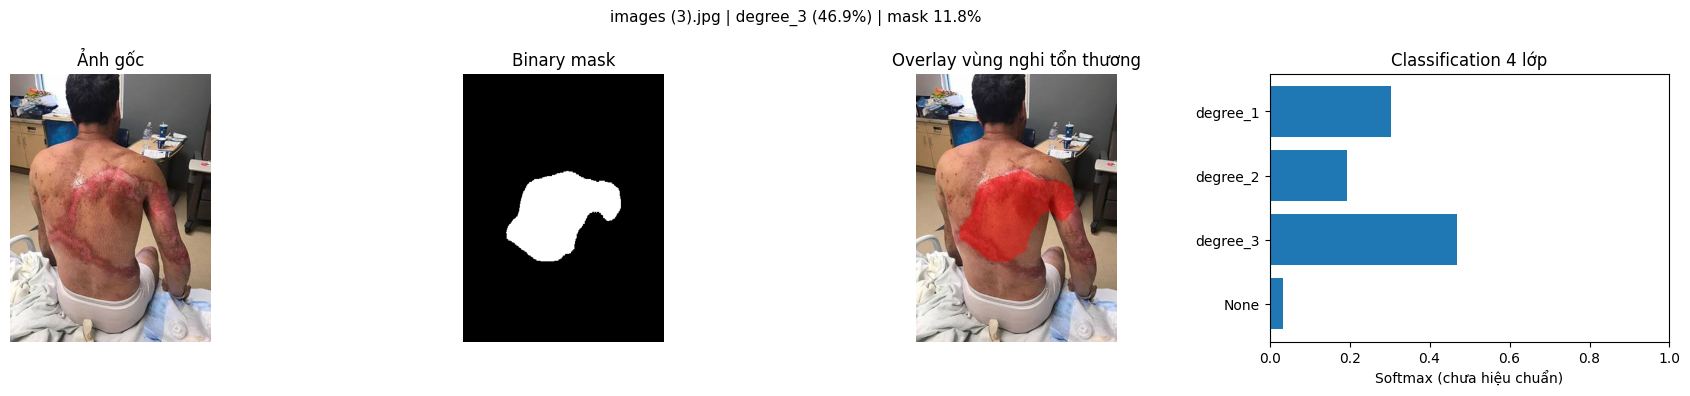

Cảnh báo: Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.
[8/16] images (4).jpg -> degree_2 (94.8%), mask=10.4%, 0.63s


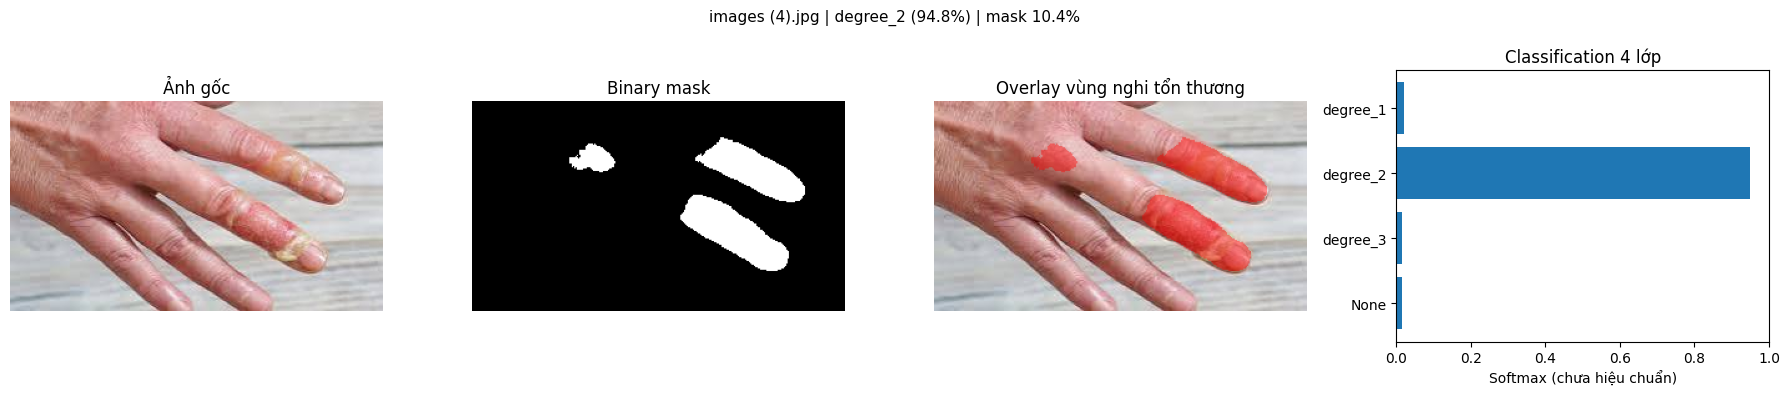

Cảnh báo: Không phát hiện bất đồng theo quy tắc cảnh báo đơn giản.
[9/16] images (6).jpg -> degree_3 (97.2%), mask=21.8%, 0.63s
[10/16] mot_so_hinh_anh_so_cuu_khi_tre_bi_bong_1_728161f5bb.jpg -> degree_2 (97.1%), mask=8.7%, 0.64s
[11/16] photo1715057937119-1715057937341359875446.webp -> degree_2 (67.3%), mask=32.2%, 0.62s
[12/16] small_20190705_131119_591877_1835871_max_1800x1800_jpg_734b0471fe.jpg -> degree_2 (97.0%), mask=12.6%, 0.64s
[13/16] tre-bi-bong-do-3-2.jpg -> degree_2 (66.0%), mask=19.1%, 0.37s
[14/16] tre-bi-bong-do-3-3.jpg -> degree_3 (67.8%), mask=42.6%, 0.35s
[15/16] vet-bong-co-mu-nhiem-trung.jpg -> degree_2 (94.1%), mask=10.3%, 0.68s
[16/16] web_face_3f0470e46b2aaf74f63b.jpg -> degree_2 (64.1%), mask=3.3%, 0.68s
✅ Đã lưu tại: /content/drive/MyDrive/Bao_Cao_Thuc_Nghiem_AI/Burn_AI_FINAL_outputs/run_20261011_131857


,filename,label,prediction_probability,mask_area_frac,disagreement,warning,inference_seconds,p_degree_1,p_degree_2,p_degree_3,p_None,width,height
0,Human_skin_structure.jpg,degree_1,0.810561,0.000000,True,Bất đồng: classifier dự đoán bỏng nhưng segmen...,0.508437,0.810561,0.155271,0.013035,0.021133,528,363
1,bong-da(2)-800x450.jpg,degree_1,0.957165,0.109063,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.929158,0.957165,0.025473,0.009717,0.007644,800,450
2,bong_cap_do_3_la_gi_dau_hieu_nhan_biet_cach_xu...,degree_2,0.915457,0.258633,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.647624,0.009203,0.915457,0.061826,0.013514,800,450
3,bong_cap_do_3_la_gi_dau_hieu_nhan_biet_cach_xu...,degree_2,0.883811,0.090117,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.602671,0.010030,0.883811,0.081411,0.024748,1920,1080
4,images (1).jpg,degree_3,0.770038,0.049912,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.692174,0.051107,0.142164,0.770038,0.036691,621,494
5,images (2).jpg,degree_3,0.983431,0.209297,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.712022,0.003355,0.005976,0.983431,0.007239,316,632
6,images (3).jpg,degree_3,0.469378,0.118086,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.802373,0.302685,0.194560,0.469378,0.033378,350,467
7,images (4).jpg,degree_2,0.948053,0.103672,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.626319,0.021504,0.948053,0.015821,0.014622,299,168
8,images (6).jpg,degree_3,0.971939,0.217744,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.631667,0.007839,0.011748,0.971939,0.008474,316,632
9,mot_so_hinh_anh_so_cuu_khi_tre_bi_bong_1_72816...,degree_2,0.970722,0.086807,False,Không phát hiện bất đồng theo quy tắc cảnh báo...,0.637581,0.008990,0.970722,0.008833,0.011456,800,600


In [38]:
# CELL 9 — SUY LUẬN TẤT CẢ ẢNH + LƯU KẾT QUẢ
stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
RUN_DIR = OUT / ('run_' + stamp)
RUN_DIR.mkdir(parents=True, exist_ok=True)
results_rows, errors = [], []

for i, image_path in enumerate(INPUT_FILES, start=1):
    safe_stem = re.sub(r'[^A-Za-z0-9_-]+', '_', Path(image_path).stem)[:50].strip('_') or 'image'
    prefix = f'{i:03d}_{safe_stem}'
    try:
        t0 = time.perf_counter()
        pred = predict_one(image_path)
        latency = time.perf_counter() - t0
        save_prediction(pred, prefix, RUN_DIR)
        row = dict(filename=Path(image_path).name, label=pred['label'],
                   prediction_probability=pred['predicted_class_probability'],
                   mask_area_frac=pred['mask_area_frac'],
                   disagreement=pred['disagreement'], warning=pred['note'],
                   inference_seconds=latency,
                   **{'p_' + k: v for k, v in pred['softmax_probs'].items()},
                   **pred['original_size'])
        results_rows.append(row)
        print(f"[{i}/{len(INPUT_FILES)}] {Path(image_path).name} -> {row['label']} ({row['prediction_probability']:.1%}), mask={row['mask_area_frac']:.1%}, {latency:.2f}s")
        if i <= cfg.MAX_PREVIEW:
            show_prediction(pred, Path(image_path).name)
    except Exception as exc:
        errors.append({'file': str(image_path), 'error': str(exc)})
        print('❌ Lỗi ảnh', image_path, ':', exc)

if results_rows:
    results_df = pd.DataFrame(results_rows)
    results_df.to_csv(RUN_DIR / 'predictions.csv', index=False, encoding='utf-8-sig')
    meta = {
        'classifier_checkpoint': str(CLS_PATH),
        'segmenter_checkpoint': str(SEG_PATH),
        'classifier_validation_macro_f1': 0.8537414965986394,
        'segmenter_validation_dice': 0.7129322742626437,
        'classes': CLASS_NAMES,
        'classifier_size': cfg.CLS_SIZE,
        'segmentation_size': cfg.SEG_SIZE,
        'mask_threshold': cfg.MASK_THRESHOLD,
        'safe_hybrid_no_hard_override': True,
        'n_success': len(results_rows), 'n_errors': len(errors),
        'notes': 'Single-label classification, binary segmentation; not clinical diagnosis.',
    }
    with (RUN_DIR / 'run_metadata.json').open('w', encoding='utf-8') as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)
    if errors:
        with (RUN_DIR / 'errors.json').open('w', encoding='utf-8') as f:
            json.dump(errors, f, ensure_ascii=False, indent=2)
    print('✅ Đã lưu tại:', RUN_DIR)
    display(results_df)
else:
    print('Không xử lý được ảnh nào. Kiểm tra log lỗi phía trên.')


In [39]:
# CELL 10 — ĐÓNG GÓI KẾT QUẢ DEMO ĐỂ NỘP (KHÔNG CHỨA TRỌNG SỐ)
if 'RUN_DIR' not in globals() or not (RUN_DIR / 'predictions.csv').exists():
    print('Chưa có predictions.csv. Chạy Cell 8 và 9 trước.')
else:
    zip_path = OUT / (RUN_DIR.name + '.zip')
    with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
        for path in sorted(RUN_DIR.rglob('*')):
            if path.is_file():
                zf.write(path, arcname=str(path.relative_to(RUN_DIR)))
    print('ZIP kết quả:', zip_path)
    if IS_COLAB:
        print('Có thể tải ZIP qua thanh Files của Colab hoặc sử dụng Drive.')


ZIP kết quả: /content/drive/MyDrive/Bao_Cao_Thuc_Nghiem_AI/Burn_AI_FINAL_outputs/run_20261011_131857.zip
Có thể tải ZIP qua thanh Files của Colab hoặc sử dụng Drive.


---
### Lưu ý khi viết báo cáo

- **Classification:** số `best_val_macro_f1` ≈ 0,8537 là kết quả **validation lưu trong checkpoint**, không phải kết quả test độc lập. Đây là mô hình **single-label**, không phải multi-label.
- **Segmentation:** checkpoint Curriculum ghi `valid_dice` ≈ 0,7129. Benchmark đã chạy trước đó trên **13 mask test**: Curriculum Dice ≈ 0,7215, manual-only v6 Dice ≈ 0,6592; mẫu test rất nhỏ nên chưa chứng minh ưu thế thống kê ổn định.
- **Safe Hybrid:** giữ quyết định của classifier và bổ sung mask/cảnh báo. Do đó **không được tuyên bố Hybrid nâng Macro-F1** so với classifier thuần khi chưa có phép thử chứng minh.
- **Phạm vi:** mask nhị phân không gán mức độ bỏng cho từng pixel. Ảnh có đồng thời nhiều mức độ vẫn chỉ được trả về **một nhãn cấp ảnh**.
- **Trách nhiệm:** Hệ thống phục vụ trình diễn, học thuật và phân tích AI; không dùng để chẩn đoán hoặc hướng dẫn điều trị bỏng.